# 04 · קשרים ומתאמים

<div dir="rtl">

## המטרה

החזירי מטריצת Spearman של העמודות המספריות בלבד. צרי heatmap ו־scatterplot לפי target. השווי קשר כולל לקשר בתוך קבוצת sex; כתבי מדוע מתאם אינו סיבתיות ומדוע קידוד קטגוריות כמספרים עלול להטעות.

זמן מומלץ: 30 דקות. קראי את `data/README.md` לפני העבודה.

## הכנה

הריצי את התא הבא. הנתונים מקומיים; אין צורך להוריד אותם שוב.

</div>

**פתרון ייחוס למורה — פתיחה רק בבקשה מפורשת.**

In [1]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.common import load
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
frame = load("heart")
frame.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## העבודה שלך

השלימי את `correlations(frame)` בקובץ `src/ex04.py`.

כתבי לפני הקוד: מה את מצפה למצוא, ואילו נתונים חסרים כדי לפרש את התוצאה?

התא הבא בטוח להרצה: הקריאה לפונקציה נשארת בהערה עד שתשלימי אותה.

In [2]:
import solutions.ex04 as student
answer = student.correlations(frame)
answer

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.099131,-0.087494,0.285617,0.195786,0.113978,-0.132769,-0.398052,0.089679,0.268291,-0.184048,0.340955,0.087254,-0.238400
sex,-0.099131,1.000000,-0.062041,-0.052941,-0.151342,0.045032,-0.048389,-0.039868,0.141664,0.100715,-0.025010,0.119368,0.250821,-0.280937
cp,-0.087494,-0.062041,1.000000,0.035413,-0.091721,0.089775,0.065640,0.324013,-0.418256,-0.161449,0.159478,-0.216006,-0.207840,0.460860
trestbps,0.285617,-0.052941,0.035413,1.000000,0.126562,0.151984,-0.125841,-0.040407,0.052918,0.154267,-0.086570,0.090140,0.059673,-0.121593
chol,0.195786,-0.151342,-0.091721,0.126562,1.000000,0.018463,-0.161933,-0.046766,0.091514,0.045260,-0.012551,0.111981,0.083628,-0.120888
fbs,0.113978,0.045032,0.089775,0.151984,0.018463,1.000000,-0.081508,-0.014273,0.025665,0.028363,-0.045786,0.134513,-0.006737,-0.028046
restecg,-0.132769,-0.048389,0.065640,-0.125841,-0.161933,-0.081508,1.000000,0.087863,-0.077399,-0.077372,0.113661,-0.097862,-0.010982,0.148612
thalach,-0.398052,-0.039868,0.324013,-0.040407,-0.046766,-0.014273,0.087863,1.000000,-0.400860,-0.433241,0.436968,-0.257347,-0.160581,0.428370
exang,0.089679,0.141664,-0.418256,0.052918,0.091514,0.025665,-0.077399,-0.400860,1.000000,0.297173,-0.274475,0.162025,0.247113,-0.436757
oldpeak,0.268291,0.100715,-0.161449,0.154267,0.045260,0.028363,-0.077372,-0.433241,0.297173,1.000000,-0.594847,0.224895,0.255026,-0.421487


<details><summary>רמז ראשון — לחצי רק אחרי ניסיון עצמאי</summary>

select_dtypes ואחריו corr(method="spearman").

</details>

<details><summary>רמז שני — איך להתקדם?</summary>

פתחי את הבדיקה `tests/test_ex04.py`, זהי ציפייה אחת, ונסי לממש אותה על טבלה קטנה. בקשי מהמורה שאלה מכוונת לפני קוד.

</details>

## חקירה והצגה

הוסיפי כאן את הגרפים וההשוואות שנדרשו במטרה. לכל גרף: כותרת, יחידות, מכנה ומשפט פרשנות. קוד ותוויות גרפים באנגלית; הדיון בעברית.

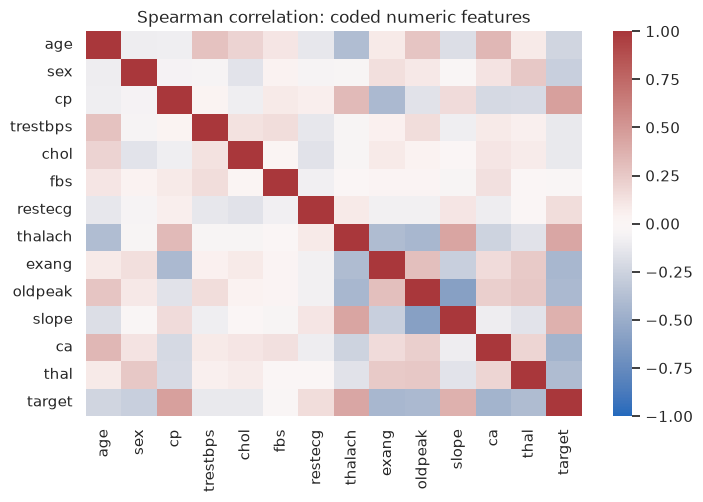

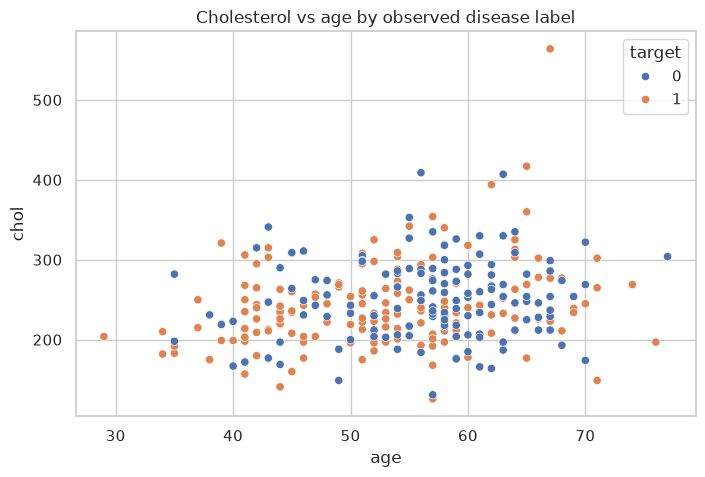

               age      chol
sex                         
0   age   1.000000  0.231259
    chol  0.231259  1.000000
1   age   1.000000  0.153485
    chol  0.153485  1.000000


In [3]:
sns.heatmap(answer, vmin=-1,vmax=1,cmap="vlag")
plt.title("Spearman correlation: coded numeric features")
plt.show()
sns.scatterplot(data=frame,x="age",y="chol",hue="target")
plt.title("Cholesterol vs age by observed disease label")
plt.show()
print(frame.groupby("sex")[["age","chol"]].corr(method="spearman"))

## בדיקה ומשוב

בטרמינל משורש המאגר:

```bash
make check EX=04
```

כישלון עם `NotImplementedError` צפוי לפני השלמת הפונקציה. הצלחת הבדיקות מאמתת רק את חוזה הקוד; היא אינה ציון לאיכות הניתוח.

מחוון מתוך 10: קוד ובדיקות 4; גרפים וחקירה 2; מניעת הטיות/דליפה 2; פרשנות ומגבלות 2. יעד מעבר: 8 וכל בדיקות הקוד עוברות.

## דיון למורה

יש לבסס מסקנה על הפלט שהורץ. דרשי הבחנה בין קשר וסיבתיות, תיאור אוכלוסיית המדגם והערכת הכללה. אין מסקנה קלינית הנובעת מציון גבוה בלבד. בתרגיל 11 הדילול משנה את שכיחות האימון ולכן עלול לפגוע בהעברת הכיול לאוכלוסיית המבחן. בתרגיל 12 השווי ל־dummy ובחני עד כמה החלוקה הגאוגרפית משנה את ההמלצה. אין תשובה מילולית יחידה: השתמשי במחוון שבמחברת להערכת ההנמקה.